# San Rafael LV Grid Impact Study
## pandapower model with stochastic household demand and NASA POWER solar data

This notebook evaluates the local distribution network around EPM transformer 94022.

The load input is the same stochastic household demand set used by the PyPSA v17 model. Solar output for the grid study is calculated independently from NASA POWER hourly irradiance.

The study checks transformer loading, MV/LV conductor loading, voltage drop, voltage rise, reverse power flow, 4 to 8-house sensitivities and transformer headroom.

The shared 5 kW inverter is connected at the transformer LV bus.

## 1. Single-phase equivalent

Transformer 94022 is a 7.621 kV / 240-120 V single-phase transformer. The standard pandapower solver uses a balanced three-phase representation, so the physical network is represented with an equivalent three-phase model.

The mapping is:

- equivalent voltage = `sqrt(3) × physical single-phase voltage`
- equivalent power = `3 × physical single-phase power`
- equivalent transformer rating = `3 × physical transformer rating`

With this mapping, per-unit voltage, conductor current and transformer loading percentage remain consistent with the physical single-phase system. Reported active power is converted back to the physical single-phase value.

For the 240 V secondary circuit, the LV line uses twice the single-conductor series impedance to represent the two-conductor current path.

## 2. Network data and assumptions

Input values are taken in the following order:

1. EPM asset data supplied for the site
2. EPM technical standards
3. manufacturer data for the identified conductor type
4. engineering assumptions where no site-specific value is available

### Site data

- transformer: 94022
- node: 931076
- circuit: 221-12
- primary voltage: 7.621 kV
- secondary voltage: 240/120 V
- transformer rating: 5 kVA
- primary conductor: #2 ACSR
- secondary conductor: 1/0 AAC
- primary route: approximately 354.2 m
- secondary route: approximately 324.5 m

### EPM references

**ET-TD-ME01-03, Cables ACSR**
- #2 AWG ACSR Sparrow
- DC resistance at 20 °C: 0.8320 Ω/km

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/ET-TD-ME01-03.pdf

**ET-TD-ME01-02, Cables AAC aislados**
- 1/0 AWG AAC
- DC resistance at 20 °C: 0.538 Ω/km

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/ET-TD-ME01-02.pdf

**ET-TD-ME01-06, Cable multiplex**
- includes 1/0 AAC phase conductors for secondary multiplex arrangements

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/ET-TD-ME01-06.pdf

**RA4-100**
- 5 kVA, 7620 V / 240-120 V single-phase transformer: 20.8 A nominal LV current

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/RA4_100.pdf

**RA8-017**
- residential calculations use power factor 0.9
- 3% voltage-drop reference from transformer secondary to metering point
- 0.656 Ω/km AC resistance reference for 1/0 aluminium conductor

https://www.epm.com.co/content/dam/epm/proveedores-y-contratistas/RA8-017.pdf

### Manufacturer reference

Nexans Colombia lists an ampacity of about 184 A for #2 ACSR Sparrow.

https://www.nexans.co/en/products/Sistemas-Solares/Granjas-Solares/Cables-solar-premium-ACSR/ACSR.html

### Values not available from the site data

The exact impedance and loss data for transformer 94022 are not available. Transformer `vk`, `vkr`, no-load loss and magnetising current are therefore kept as explicit assumptions at the top of the notebook.

The installation-specific reactance and ampacity of the local 1/0 AAC secondary are also not known. Line-loading results should therefore be treated as screening values.

## 3. Installation and input files

Install the required packages with:

```bash
pip install -r SanRafael_pandapower_requirements.txt
```

Required inputs:

- `stochastic_household_load_profiles.csv`, generated by the PyPSA v17 notebook
- `NASA_POWER_SanRafael_hourly_2025.csv`

The stochastic file contains individual household profiles and aggregate profiles for groups up to 20 houses.

Results are written to `pandapower_results_nasa/`.

In [1]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pvlib

try:
    from IPython.display import display, Image
except ImportError:
    display = print
    Image = None

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
RESULTS_DIR = ROOT / "pandapower_results_nasa"
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print("pandapower version:", pp.__version__)
print("pvlib version:", pvlib.__version__)
print("Working directory:", ROOT.resolve())

pandapower version: 3.4.0
pvlib version: 0.15.0
Working directory: D:\0. UoL\SEEDExchange\sanrafaelutility-main


In [2]:
# ============================================================
# 4. GLOBAL CONFIGURATION
# ============================================================

# Grouping configurations
HOUSE_COUNTS = [4, 5, 6, 7, 8]
HOUSES_PER_TAP = 2

# Stochastic demand profiles use the HOMER settings:
# 20% day-to-day variability and 25% timestep variability.
STOCHASTIC_LOAD_SEED = 20250913
STOCHASTIC_PROFILE_HOUSE_COUNT = 20

# Electrical source / transformer
TRF_NUMBER = 94022
TRF_NODE = 931076
CIRCUIT = "221-12"

MV_PHYSICAL_KV = 7.621
LV_PHYSICAL_KV = 0.240
TRF_PHYSICAL_KVA = 5.0

# Single-phase -> balanced pandapower equivalent
PP_POWER_SCALE = 3.0
MV_EQ_KV = math.sqrt(3) * MV_PHYSICAL_KV
LV_EQ_KV = math.sqrt(3) * LV_PHYSICAL_KV
TRF_EQ_MVA = PP_POWER_SCALE * TRF_PHYSICAL_KVA / 1000.0

# Image-derived route lengths
MV_ROUTE_M = 354.2
LV_ROUTE_M = 324.5

# Residential power factor.
# EPM RA8-017 uses fp = 0.9 in its residential conductor calculations.
LOAD_POWER_FACTOR = 0.90

# ------------------------------------------------------------
# NASA / PV configuration
# ------------------------------------------------------------

SITE_LAT = 6.2523
SITE_LON = -75.0143
SITE_ALTITUDE_M = 1291.33

PV_ARRAY_KWP = 5.22
PV_SURFACE_TILT_DEG = 5.0

# pvlib convention: 180 degrees = south.
# This is used as the equator-facing interpretation of the
# HOMER 0-degree azimuth setting. At 5-degree tilt the azimuth
# sensitivity is small.
PV_SURFACE_AZIMUTH_DEG = 180.0

PV_DERATING_FACTOR = 0.80
PV_TEMP_COEFF_PER_C = -0.003
PV_NOCT_C = 45.0

INVERTER_AC_LIMIT_KW = 5.0
INVERTER_EFFICIENCY = 0.95

HOMER_REFERENCE_PV_DC_KWH = 7326.3

# NASA file was downloaded with time-standard=LST.
# The site longitude is almost exactly the UTC-5 standard meridian,
# so the hourly labels are aligned directly to the project's 2025
# load-clock timestamps for this grid-screening study.
NASA_TIMEZONE_FOR_SOLAR_POSITION = "Etc/GMT+5"

# ------------------------------------------------------------
# EPM / literature-based conductor values
# ------------------------------------------------------------

# #2 ACSR Sparrow, EPM ET-TD-ME01-03
MV_R_OHM_PER_KM = 0.8320

# Reactance is installation / geometry dependent.
MV_X_OHM_PER_KM = 0.40

# Supplementary manufacturer reference for #2 ACSR Sparrow.
MV_MAX_I_KA = 0.184

# 1/0 AAC:
# EPM ET-TD-ME01-02 gives 0.538 ohm/km DC at 20 C.
# EPM RA8-017 gives 0.656 ohm/km AC as a 1/0 Al reference.
LV_R_SINGLE_OHM_PER_KM = 0.656

# Installation-specific reactance is not available.
LV_X_SINGLE_OHM_PER_KM = 0.08

# 240 V current flows through a two-conductor loop.
LV_R_LOOP_OHM_PER_KM = 2 * LV_R_SINGLE_OHM_PER_KM
LV_X_LOOP_OHM_PER_KM = 2 * LV_X_SINGLE_OHM_PER_KM

# Screening ampacity pending exact installation-specific value.
LV_MAX_I_KA = 0.150

# ------------------------------------------------------------
# Transformer parameters
# ------------------------------------------------------------
# Exact nameplate data for transformer 94022 are not available.
# These remain engineering proxies.

TRF_VK_PERCENT = 3.0
TRF_VKR_PERCENT = 1.8
TRF_PFE_PHYSICAL_KW = 0.030
TRF_I0_PERCENT = 2.5

# ------------------------------------------------------------
# Voltage / loading screening references
# ------------------------------------------------------------

LV_SCREEN_MIN_PU = 0.97
LV_SCREEN_MAX_PU = 1.03

TRF_NOMINAL_LIMIT_PERCENT = 100.0
LINE_LIMIT_PERCENT = 100.0

# ------------------------------------------------------------
# Deterministic DER stress cases
# ------------------------------------------------------------

CLEAR_SKY_INVERTER_KW = [4.0, 4.5, 5.0]

# Optional transformer headroom study.
HEADROOM_HOUSE_COUNTS = list(range(1, 21))

In [3]:
# ============================================================
# 5. ROBUST INPUT LOCATOR
# ============================================================

SEARCH_DIRS = [
    ROOT,
    ROOT / "results",
    ROOT / "data",
    ROOT / "NASA Data",
    ROOT.parent,
]

def find_input(candidates, required=True):
    for directory in SEARCH_DIRS:
        for name in candidates:
            p = directory / name
            if p.exists():
                return p

    for directory in SEARCH_DIRS:
        if not directory.exists():
            continue
        for name in candidates:
            hits = list(directory.rglob(name))
            if hits:
                return hits[0]

    if required:
        raise FileNotFoundError(
            "Could not find any of:\n- " + "\n- ".join(candidates)
        )
    return None


STOCHASTIC_LOAD_PATH = find_input([
    "stochastic_household_load_profiles.csv",
])

HANDOFF_PATH = find_input([
    "pandapower_handoff_S2_REFERENCE_PV_BESS.csv",
    "pandapower_handoff_S2_REFERENCE_PV_BESS(3).csv",
    "pandapower_handoff_S2_REFERENCE_PV_BESS(2).csv",
    "pandapower_handoff_S2_REFERENCE_PV_BESS(1).csv",
], required=False)

NASA_PATH = find_input([
    "NASA_POWER_SanRafael_hourly_2025.csv",
])

METADATA_PATH = find_input([
    "pandapower_metadata_S2_REFERENCE_PV_BESS.csv",
    "pandapower_metadata_S2_REFERENCE_PV_BESS(3).csv",
    "pandapower_metadata_S2_REFERENCE_PV_BESS(2).csv",
    "pandapower_metadata_S2_REFERENCE_PV_BESS(1).csv",
], required=False)

CORE_CASES_PATH = find_input([
    "core_cases.csv",
    "core_cases(7).csv",
    "core_cases(6).csv",
    "core_cases(5).csv",
], required=False)

ASSET_PATH = find_input([
    "san_rafael_epm_asset_94022.csv",
], required=False)

GEOMETRY_PATH = find_input([
    "san_rafael_epm_local_geometry_v2.csv",
], required=False)

print("Stochastic household load file:", STOCHASTIC_LOAD_PATH)
print("Optional PyPSA handoff:", HANDOFF_PATH)
print("NASA POWER hourly file:", NASA_PATH)
print("PyPSA metadata:", METADATA_PATH)
print("Core cases:", CORE_CASES_PATH)
print("Asset file:", ASSET_PATH)
print("Geometry file:", GEOMETRY_PATH)

Stochastic household load file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\stochastic_household_load_profiles.csv
Optional PyPSA handoff: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_handoff_S2_REFERENCE_PV_BESS.csv
NASA POWER hourly file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\NASA_POWER_SanRafael_hourly_2025.csv
PyPSA metadata: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\pandapower_metadata_S2_REFERENCE_PV_BESS.csv
Core cases: d:\0. UoL\SEEDExchange\sanrafaelutility-main\results\core_cases.csv
Asset file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\SanRafael_Reproducible_Model_Package_v1\SanRafael_Reproducible_Model_Package\04_grid_data\san_rafael_epm_asset_94022.csv
Geometry file: d:\0. UoL\SEEDExchange\sanrafaelutility-main\SanRafael_Reproducible_Model_Package_v1\SanRafael_Reproducible_Model_Package\04_grid_data\san_rafael_epm_local_geometry_v2.csv


In [4]:
# ============================================================
# 6. LOAD SOURCE DATA
# ============================================================

stochastic_loads = pd.read_csv(
    STOCHASTIC_LOAD_PATH,
    parse_dates=["timestamp"],
)

nasa = pd.read_csv(
    NASA_PATH,
    parse_dates=["timestamp_lst"],
)

handoff = (
    pd.read_csv(HANDOFF_PATH, parse_dates=["timestamp"])
    if HANDOFF_PATH is not None
    else pd.DataFrame()
)

metadata = (
    pd.read_csv(METADATA_PATH)
    if METADATA_PATH is not None
    else pd.DataFrame()
)

core_cases = (
    pd.read_csv(CORE_CASES_PATH)
    if CORE_CASES_PATH is not None
    else pd.DataFrame()
)

asset = (
    pd.read_csv(ASSET_PATH)
    if ASSET_PATH is not None
    else pd.DataFrame()
)

geometry = (
    pd.read_csv(GEOMETRY_PATH)
    if GEOMETRY_PATH is not None
    else pd.DataFrame()
)

required_house_columns = {
    f"house_{h}_kw"
    for h in range(1, STOCHASTIC_PROFILE_HOUSE_COUNT + 1)
}

required_group_columns = {
    f"load_{h}hh_kw"
    for h in range(1, STOCHASTIC_PROFILE_HOUSE_COUNT + 1)
}

missing = (
    {"timestamp"}
    | required_house_columns
    | required_group_columns
) - set(stochastic_loads.columns)

if missing:
    raise ValueError(
        "Stochastic load file is missing required columns:\n"
        + "\n".join(sorted(missing))
    )

required_nasa_columns = {
    "timestamp_lst",
    "ALLSKY_SFC_SW_DWN",
    "ALLSKY_SFC_SW_DIFF",
    "ALLSKY_SFC_SW_DNI",
    "CLRSKY_SFC_SW_DWN",
    "T2M",
    "WS10M",
}

missing = required_nasa_columns - set(nasa.columns)

if missing:
    raise ValueError(
        f"NASA hourly file is missing required columns: {sorted(missing)}"
    )

for col in sorted(required_nasa_columns - {"timestamp_lst"}):
    nasa[col] = pd.to_numeric(nasa[col], errors="coerce")
    nasa.loc[nasa[col] <= -900, col] = np.nan

if nasa[list(required_nasa_columns - {"timestamp_lst"})].isna().any().any():
    raise ValueError("NASA hourly file contains missing/fill values")

load_summary = pd.DataFrame([
    {
        "houses": houses,
        "annual_load_kwh":
            stochastic_loads[f"load_{houses}hh_kw"].sum(),
        "peak_load_kw":
            stochastic_loads[f"load_{houses}hh_kw"].max(),
        "average_load_kw":
            stochastic_loads[f"load_{houses}hh_kw"].mean(),
    }
    for houses in HOUSE_COUNTS
])

display(load_summary.round(4))

,houses,annual_load_kwh,peak_load_kw,average_load_kw
0,4,7592.0,2.1667,0.8667
1,5,9490.0,2.5193,1.0833
2,6,11388.0,2.9979,1.3000
3,7,13286.0,3.7174,1.5167
4,8,15184.0,4.1833,1.7333


## 7. PV profile from NASA POWER

The pandapower study uses an independent hourly PV profile. The PyPSA solar profile is not used.

The conversion is:

1. NASA hourly GHI, DNI and DHI
2. solar position from pvlib
3. plane-of-array irradiance for the 5° array
4. NOCT cell-temperature estimate
5. 5.22 kWp DC array
6. 80% PV derating
7. temperature coefficient of -0.3%/°C
8. 95% inverter efficiency
9. 5 kW AC inverter limit

The resulting annual PV energy is not rescaled to the HOMER result. HOMER's 7,326.3 kWh/year is shown only as a reference.

For the annual grid-impact run, the battery is taken as full or idle. It does not absorb PV surplus or discharge to reduce evening demand. This gives a conservative network-loading envelope rather than a storage dispatch simulation.

In [5]:
# ============================================================
# 7A. BUILD NASA-DERIVED HOURLY PV PROFILE
# ============================================================

nasa_for_merge = nasa.rename(
    columns={"timestamp_lst": "timestamp"}
).copy()

annual_inputs = (
    stochastic_loads
    .merge(
        nasa_for_merge,
        on="timestamp",
        how="inner",
        validate="one_to_one",
    )
    .sort_values("timestamp")
    .reset_index(drop=True)
)

annual_inputs["load_kw"] = annual_inputs["load_4hh_kw"]

if len(annual_inputs) != 8760:
    raise ValueError(
        f"Load/NASA timestamp alignment produced {len(annual_inputs)} rows, "
        "expected 8760. Check time standards and timestamps."
    )

# NASA file uses Local Solar Time. For solar-position calculation,
# use the local UTC-5 clock because this site's longitude is nearly
# exactly the -75 degree UTC-5 standard meridian.
solar_times = pd.DatetimeIndex(
    annual_inputs["timestamp"]
).tz_localize(
    NASA_TIMEZONE_FOR_SOLAR_POSITION
)

solar_position = pvlib.solarposition.get_solarposition(
    time=solar_times,
    latitude=SITE_LAT,
    longitude=SITE_LON,
    altitude=SITE_ALTITUDE_M,
)

poa = pvlib.irradiance.get_total_irradiance(
    surface_tilt=PV_SURFACE_TILT_DEG,
    surface_azimuth=PV_SURFACE_AZIMUTH_DEG,
    solar_zenith=solar_position["apparent_zenith"].to_numpy(),
    solar_azimuth=solar_position["azimuth"].to_numpy(),
    dni=annual_inputs["ALLSKY_SFC_SW_DNI"].to_numpy(),
    ghi=annual_inputs["ALLSKY_SFC_SW_DWN"].to_numpy(),
    dhi=annual_inputs["ALLSKY_SFC_SW_DIFF"].to_numpy(),
    albedo=0.20,
    model="isotropic",
)

annual_inputs["poa_global_wm2"] = np.clip(
    np.asarray(poa["poa_global"], dtype=float),
    0.0,
    None,
)

# NOCT cell-temperature approximation.
annual_inputs["cell_temperature_c"] = (
    annual_inputs["T2M"]
    + (
        (PV_NOCT_C - 20.0)
        / 800.0
        * annual_inputs["poa_global_wm2"]
    )
)

temperature_factor = (
    1.0
    + PV_TEMP_COEFF_PER_C
    * (
        annual_inputs["cell_temperature_c"]
        - 25.0
    )
)

temperature_factor = np.clip(
    temperature_factor,
    0.0,
    None,
)

annual_inputs["nasa_pv_dc_kw"] = (
    PV_ARRAY_KWP
    * annual_inputs["poa_global_wm2"]
    / 1000.0
    * PV_DERATING_FACTOR
    * temperature_factor
)

annual_inputs["nasa_pv_ac_kw_unclipped"] = (
    annual_inputs["nasa_pv_dc_kw"]
    * INVERTER_EFFICIENCY
)

annual_inputs["nasa_pv_ac_kw"] = np.minimum(
    annual_inputs["nasa_pv_ac_kw_unclipped"],
    INVERTER_AC_LIMIT_KW,
)

annual_inputs["inverter_clipped"] = (
    annual_inputs["nasa_pv_ac_kw_unclipped"]
    > INVERTER_AC_LIMIT_KW
)

nasa_pv_dc_kwh = float(
    annual_inputs["nasa_pv_dc_kw"].sum()
)

nasa_pv_ac_kwh = float(
    annual_inputs["nasa_pv_ac_kw"].sum()
)

pv_comparison = pd.DataFrame([
    {
        "metric": "NASA-derived PV DC annual energy",
        "value": nasa_pv_dc_kwh,
        "unit": "kWh/year",
    },
    {
        "metric": "NASA-derived inverter AC annual energy",
        "value": nasa_pv_ac_kwh,
        "unit": "kWh/year",
    },
    {
        "metric": "HOMER PV DC reference",
        "value": HOMER_REFERENCE_PV_DC_KWH,
        "unit": "kWh/year",
    },
    {
        "metric": "NASA DC / HOMER DC",
        "value": 100.0 * nasa_pv_dc_kwh / HOMER_REFERENCE_PV_DC_KWH,
        "unit": "%",
    },
    {
        "metric": "Maximum NASA-derived PV DC",
        "value": annual_inputs["nasa_pv_dc_kw"].max(),
        "unit": "kW",
    },
    {
        "metric": "Maximum NASA-derived inverter AC",
        "value": annual_inputs["nasa_pv_ac_kw"].max(),
        "unit": "kW",
    },
    {
        "metric": "Hours at 5 kW inverter clipping",
        "value": int(annual_inputs["inverter_clipped"].sum()),
        "unit": "hours",
    },
])

display(pv_comparison.round(4))

pv_comparison.to_csv(
    RESULTS_DIR / "nasa_pv_profile_summary.csv",
    index=False,
)

annual_inputs.to_csv(
    RESULTS_DIR / "nasa_hourly_pv_and_load_inputs.csv",
    index=False,
)

# Compare only the peak if the old finalized PyPSA handoff contains
# its synthetic inverter output. It remains diagnostic and is not used
# in the NASA pandapower power flow.
if (not handoff.empty and "inverter_ac_output_kw" in handoff.columns):
    comparison = pd.DataFrame([
        {
            "profile": "Finalized PyPSA synthetic solar",
            "peak_inverter_ac_kw":
                handoff["inverter_ac_output_kw"].max(),
        },
        {
            "profile": "NASA-hourly pandapower solar",
            "peak_inverter_ac_kw":
                annual_inputs["nasa_pv_ac_kw"].max(),
        },
    ])
    display(comparison.round(4))

,metric,value,unit
0,NASA-derived PV DC annual energy,6338.7052,kWh/year
1,NASA-derived inverter AC annual energy,6021.7700,kWh/year
2,HOMER PV DC reference,7326.3000,kWh/year
3,NASA DC / HOMER DC,86.5199,%
4,Maximum NASA-derived PV DC,4.8879,kW
5,Maximum NASA-derived inverter AC,4.6436,kW
6,Hours at 5 kW inverter clipping,0.0000,hours


,profile,peak_inverter_ac_kw
0,Finalized PyPSA synthetic solar,2.7651
1,NASA-hourly pandapower solar,4.6436


## 8. Operating cases

The stochastic household profiles are used throughout the network study.

### Hourly 2025 run

Each house keeps its own stochastic demand value. PV output is calculated from NASA POWER data and the battery is idle.

### Inverter stress cases

The 4.0, 4.5 and 5.0 kW inverter cases use the minimum daytime stochastic load for each group, including the individual household values at that hour.

In [6]:
# ============================================================
# 9. PROVENANCE TABLE
# ============================================================

provenance = pd.DataFrame([
    {
        "parameter": "Transformer 94022 rating",
        "value": "5 kVA",
        "status": "Actual EPM asset",
        "source": "Project EPM asset data",
    },
    {
        "parameter": "Transformer primary / secondary",
        "value": "7.621 kV / 240-120 V",
        "status": "Actual EPM asset",
        "source": "Project EPM asset data",
    },
    {
        "parameter": "Primary route",
        "value": f"{MV_ROUTE_M:.1f} m",
        "status": "Image-derived approximate",
        "source": "EPM screenshot trace",
    },
    {
        "parameter": "Secondary route",
        "value": f"{LV_ROUTE_M:.1f} m",
        "status": "Image-derived approximate",
        "source": "Corrected EPM secondary trace",
    },
    {
        "parameter": "#2 ACSR resistance",
        "value": f"{MV_R_OHM_PER_KM:.4f} ohm/km @20 C",
        "status": "Official EPM technical literature",
        "source": "ET-TD-ME01-03",
    },
    {
        "parameter": "1/0 AAC resistance reference",
        "value": f"{LV_R_SINGLE_OHM_PER_KM:.3f} ohm/km",
        "status": "Official EPM design reference",
        "source": "RA8-017 / ET-TD-ME01-02",
    },
    {
        "parameter": "#2 ACSR ampacity",
        "value": f"{MV_MAX_I_KA*1000:.0f} A",
        "status": "Supplementary manufacturer reference",
        "source": "Nexans Colombia",
    },
    {
        "parameter": "1/0 AAC ampacity",
        "value": f"{LV_MAX_I_KA*1000:.0f} A",
        "status": "Engineering screening assumption",
        "source": "Replace with exact installation-specific value if obtained",
    },
    {
        "parameter": "Transformer vk / vkr",
        "value": f"{TRF_VK_PERCENT:.1f}% / {TRF_VKR_PERCENT:.1f}%",
        "status": "Engineering proxy",
        "source": "Exact 94022 nameplate not available",
    },
    {
        "parameter": "Load power factor",
        "value": f"{LOAD_POWER_FACTOR:.2f}",
        "status": "EPM residential calculation reference",
        "source": "RA8-017",
    },
    {
        "parameter": "Hourly solar resource",
        "value": "2025 hourly GHI/DHI/DNI/T2M/WS10M",
        "status": "NASA POWER hourly dataset",
        "source": "NASA_POWER_SanRafael_hourly_2025.csv",
    },
    {
        "parameter": "PV array",
        "value": f"{PV_ARRAY_KWP:.2f} kWp, {PV_SURFACE_TILT_DEG:.1f} degree tilt",
        "status": "HOMER / quotation reference",
        "source": "Finalized project reference system",
    },
    {
        "parameter": "PV derating / inverter efficiency",
        "value": f"{PV_DERATING_FACTOR:.2f} / {INVERTER_EFFICIENCY:.2f}",
        "status": "HOMER reference",
        "source": "Finalized project reference system",
    },
])

display(provenance)

provenance.to_csv(
    RESULTS_DIR / "pandapower_parameter_provenance.csv",
    index=False,
)

,parameter,value,status,source
0,Transformer 94022 rating,5 kVA,Actual EPM asset,Project EPM asset data
1,Transformer primary / secondary,7.621 kV / 240-120 V,Actual EPM asset,Project EPM asset data
2,Primary route,354.2 m,Image-derived approximate,EPM screenshot trace
3,Secondary route,324.5 m,Image-derived approximate,Corrected EPM secondary trace
4,#2 ACSR resistance,0.8320 ohm/km @20 C,Official EPM technical literature,ET-TD-ME01-03
5,1/0 AAC resistance reference,0.656 ohm/km,Official EPM design reference,RA8-017 / ET-TD-ME01-02
6,#2 ACSR ampacity,184 A,Supplementary manufacturer reference,Nexans Colombia
7,1/0 AAC ampacity,150 A,Engineering screening assumption,Replace with exact installation-specific value...
8,Transformer vk / vkr,3.0% / 1.8%,Engineering proxy,Exact 94022 nameplate not available
9,Load power factor,0.90,EPM residential calculation reference,RA8-017


In [7]:
# ============================================================
# 9. SINGLE-PHASE EQUIVALENT HELPERS
# ============================================================

def physical_kw_to_pp_mw(p_kw):
    return PP_POWER_SCALE * float(p_kw) / 1000.0

def pp_mw_to_physical_kw(p_mw):
    return float(p_mw) * 1000.0 / PP_POWER_SCALE

def physical_kvar_to_pp_mvar(q_kvar):
    return PP_POWER_SCALE * float(q_kvar) / 1000.0

def q_from_p_pf(p_kw, pf):
    p_kw = float(p_kw)
    if p_kw == 0:
        return 0.0
    phi = math.acos(pf)
    return abs(p_kw) * math.tan(phi)

def n_taps_for_houses(houses):
    return int(math.ceil(houses / HOUSES_PER_TAP))

def tap_house_counts(houses):
    remaining = int(houses)
    counts = []
    while remaining > 0:
        count = min(HOUSES_PER_TAP, remaining)
        counts.append(count)
        remaining -= count
    return counts

print("Equivalent MV line-line voltage:", round(MV_EQ_KV, 4), "kV")
print("Equivalent LV line-line voltage:", round(LV_EQ_KV, 4), "kV")
print("Equivalent transformer rating:", round(TRF_EQ_MVA * 1000, 3), "kVA")
print("Physical transformer nominal LV current:", round(TRF_PHYSICAL_KVA / LV_PHYSICAL_KV, 2), "A")

Equivalent MV line-line voltage: 13.2 kV
Equivalent LV line-line voltage: 0.4157 kV
Equivalent transformer rating: 15.0 kVA
Physical transformer nominal LV current: 20.83 A


In [8]:
# ============================================================
# 10. BUILD REPRESENTATIVE RADIAL NETWORK
# ============================================================

def build_group_network(houses):
    houses = int(houses)
    if houses < 1:
        raise ValueError("houses must be >= 1")

    net = pp.create_empty_network(
        name=f"San Rafael {houses}-house representative group",
        f_hz=60.0,
        sn_mva=1.0,
    )

    # Equivalent balanced buses
    b_upstream = pp.create_bus(
        net,
        vn_kv=MV_EQ_KV,
        name="UPSTREAM_MV_EQ",
        type="b",
    )

    b_trafo_hv = pp.create_bus(
        net,
        vn_kv=MV_EQ_KV,
        name="TRF_94022_HV_EQ",
        type="b",
    )

    b_trafo_lv = pp.create_bus(
        net,
        vn_kv=LV_EQ_KV,
        name="TRF_94022_LV_EQ",
        type="b",
    )

    pp.create_ext_grid(
        net,
        bus=b_upstream,
        vm_pu=1.0,
        name="EPM_UPSTREAM",
    )

    # Local primary branch.
    pp.create_line_from_parameters(
        net,
        from_bus=b_upstream,
        to_bus=b_trafo_hv,
        length_km=MV_ROUTE_M / 1000.0,
        r_ohm_per_km=MV_R_OHM_PER_KM,
        x_ohm_per_km=MV_X_OHM_PER_KM,
        c_nf_per_km=0.0,
        max_i_ka=MV_MAX_I_KA,
        name="MV_LOCAL_#2_ACSR",
    )

    # 3x transformer equivalent preserves physical loading percentage.
    pp.create_transformer_from_parameters(
        net,
        hv_bus=b_trafo_hv,
        lv_bus=b_trafo_lv,
        sn_mva=TRF_EQ_MVA,
        vn_hv_kv=MV_EQ_KV,
        vn_lv_kv=LV_EQ_KV,
        vk_percent=TRF_VK_PERCENT,
        vkr_percent=TRF_VKR_PERCENT,
        pfe_kw=PP_POWER_SCALE * TRF_PFE_PHYSICAL_KW,
        i0_percent=TRF_I0_PERCENT,
        shift_degree=0.0,
        name="TRF_94022_EQ",
    )

    # Shared community inverter is connected ONLY at transformer LV bus.
    inverter_idx = pp.create_sgen(
        net,
        bus=b_trafo_lv,
        p_mw=0.0,
        q_mvar=0.0,
        name="SHARED_INVERTER_5KW",
    )

    # Representative LV radial trunk.
    # The image-derived total secondary route is divided evenly across
    # the required number of taps. Up to two houses connect at each tap.
    tap_counts = tap_house_counts(houses)
    segment_length_km = (
        LV_ROUTE_M / len(tap_counts) / 1000.0
    )

    previous_bus = b_trafo_lv
    load_indices = []
    lv_bus_indices = [b_trafo_lv]
    lv_line_indices = []

    house_number = 1

    for tap_no, house_count_at_tap in enumerate(tap_counts, start=1):
        tap_bus = pp.create_bus(
            net,
            vn_kv=LV_EQ_KV,
            name=f"LV_TAP_{tap_no}",
            type="b",
        )
        lv_bus_indices.append(tap_bus)

        line_idx = pp.create_line_from_parameters(
            net,
            from_bus=previous_bus,
            to_bus=tap_bus,
            length_km=segment_length_km,
            r_ohm_per_km=LV_R_LOOP_OHM_PER_KM,
            x_ohm_per_km=LV_X_LOOP_OHM_PER_KM,
            c_nf_per_km=0.0,
            max_i_ka=LV_MAX_I_KA,
            name=f"LV_TRUNK_{tap_no}_1/0_AAC_LOOP",
        )
        lv_line_indices.append(line_idx)

        for _ in range(house_count_at_tap):
            load_idx = pp.create_load(
                net,
                bus=tap_bus,
                p_mw=0.0,
                q_mvar=0.0,
                name=f"HOUSE_{house_number}",
            )
            load_indices.append(load_idx)
            house_number += 1

        previous_bus = tap_bus

    net._san_rafael = {
        "houses": houses,
        "upstream_bus": b_upstream,
        "trafo_hv_bus": b_trafo_hv,
        "trafo_lv_bus": b_trafo_lv,
        "lv_bus_indices": lv_bus_indices,
        "load_indices": load_indices,
        "inverter_idx": inverter_idx,
        "lv_line_indices": lv_line_indices,
    }

    return net


def set_operating_point(
    net,
    total_load_kw=None,
    inverter_ac_kw=0.0,
    house_loads_kw=None,
    load_pf=LOAD_POWER_FACTOR,
):
    houses = net._san_rafael["houses"]
    load_indices = net._san_rafael["load_indices"]
    inverter_idx = net._san_rafael["inverter_idx"]

    if house_loads_kw is None:
        if total_load_kw is None:
            raise ValueError(
                "Provide total_load_kw or house_loads_kw"
            )

        house_loads = np.full(
            houses,
            float(total_load_kw) / houses,
            dtype=float,
        )
    else:
        house_loads = np.asarray(
            house_loads_kw,
            dtype=float,
        )

        if len(house_loads) != houses:
            raise ValueError(
                f"Expected {houses} household loads, received {len(house_loads)}"
            )

        if (house_loads < 0).any():
            raise ValueError("Household demand cannot be negative")

    for idx, p_house_kw in zip(load_indices, house_loads):
        q_house_kvar = q_from_p_pf(
            p_house_kw,
            load_pf,
        )

        net.load.at[idx, "p_mw"] = physical_kw_to_pp_mw(
            p_house_kw
        )

        net.load.at[idx, "q_mvar"] = physical_kvar_to_pp_mvar(
            q_house_kvar
        )

    net.sgen.at[inverter_idx, "p_mw"] = physical_kw_to_pp_mw(
        inverter_ac_kw
    )
    net.sgen.at[inverter_idx, "q_mvar"] = 0.0


def solve_network(net):
    pp.runpp(
        net,
        algorithm="bfsw",
        init="flat",
        calculate_voltage_angles=False,
        max_iteration=100,
        tolerance_mva=1e-9,
    )
    return net

In [9]:
# ============================================================
# 11. RESULT EXTRACTION
# ============================================================

def extract_snapshot_results(
    net,
    scenario,
    total_load_kw,
    inverter_ac_kw,
):
    lv_buses = net._san_rafael["lv_bus_indices"]
    lv_lines = net._san_rafael["lv_line_indices"]

    ext_grid_import_kw = pp_mw_to_physical_kw(
        net.res_ext_grid["p_mw"].sum()
    )

    trafo_loading = float(
        net.res_trafo["loading_percent"].iloc[0]
    )

    trafo_lv_current_a = float(
        net.res_trafo["i_lv_ka"].iloc[0] * 1000.0
    )

    mv_line_idx = net.line.index[
        net.line["name"] == "MV_LOCAL_#2_ACSR"
    ][0]

    max_mv_line_loading = float(
        net.res_line.at[mv_line_idx, "loading_percent"]
    )

    max_lv_line_loading = (
        float(
            net.res_line.loc[
                lv_lines,
                "loading_percent"
            ].max()
        )
        if lv_lines
        else np.nan
    )

    min_lv_vm_pu = float(
        net.res_bus.loc[
            lv_buses,
            "vm_pu"
        ].min()
    )

    max_lv_vm_pu = float(
        net.res_bus.loc[
            lv_buses,
            "vm_pu"
        ].max()
    )

    return {
        "scenario": scenario,
        "houses": net._san_rafael["houses"],
        "load_kw": float(total_load_kw),
        "inverter_ac_kw": float(inverter_ac_kw),
        "net_demand_before_losses_kw":
            float(total_load_kw - inverter_ac_kw),
        "pcc_import_physical_kw":
            ext_grid_import_kw,
        "transformer_loading_pct":
            trafo_loading,
        "transformer_lv_current_a":
            trafo_lv_current_a,
        "max_mv_line_loading_pct":
            max_mv_line_loading,
        "max_lv_line_loading_pct":
            max_lv_line_loading,
        "min_lv_vm_pu":
            min_lv_vm_pu,
        "max_lv_vm_pu":
            max_lv_vm_pu,
        "lv_drop_screen_ok":
            min_lv_vm_pu >= LV_SCREEN_MIN_PU,
        "lv_rise_screen_ok":
            max_lv_vm_pu <= LV_SCREEN_MAX_PU,
        "transformer_nominal_ok":
            trafo_loading <= TRF_NOMINAL_LIMIT_PERCENT,
        "line_loading_ok":
            (
                max_mv_line_loading <= LINE_LIMIT_PERCENT
                and max_lv_line_loading <= LINE_LIMIT_PERCENT
            ),
    }


def run_snapshot(
    houses,
    scenario,
    total_load_kw=None,
    inverter_ac_kw=0.0,
    house_loads_kw=None,
):
    net = build_group_network(houses)
    set_operating_point(
        net,
        total_load_kw=total_load_kw,
        inverter_ac_kw=inverter_ac_kw,
        house_loads_kw=house_loads_kw,
    )
    solve_network(net)

    if house_loads_kw is not None:
        total_load_kw = float(
            np.asarray(house_loads_kw, dtype=float).sum()
        )

    result = extract_snapshot_results(
        net,
        scenario=scenario,
        total_load_kw=total_load_kw,
        inverter_ac_kw=inverter_ac_kw,
    )

    return net, result

,element,name,index
0,bus,UPSTREAM_MV_EQ,0
1,bus,TRF_94022_HV_EQ,1
2,bus,TRF_94022_LV_EQ,2
3,bus,LV_TAP_1,3
4,bus,LV_TAP_2,4
5,line,MV_LOCAL_#2_ACSR,0
6,line,LV_TRUNK_1_1/0_AAC_LOOP,1
7,line,LV_TRUNK_2_1/0_AAC_LOOP,2
8,transformer,TRF_94022_EQ,0


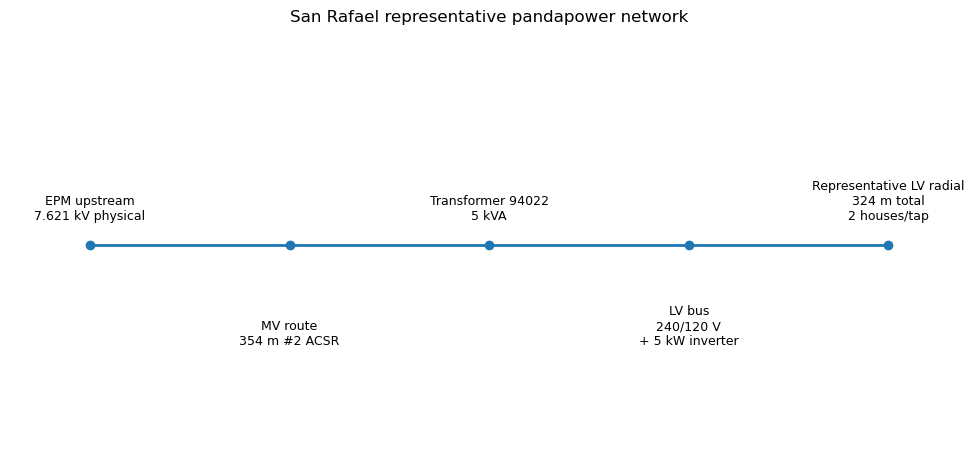

In [10]:
# ============================================================
# 12. REPRESENTATIVE NETWORK TOPOLOGY
# ============================================================

reference_net = build_group_network(4)

topology_rows = []

for idx, row in reference_net.bus.iterrows():
    topology_rows.append({
        "element": "bus",
        "name": row["name"],
        "index": idx,
    })

for idx, row in reference_net.line.iterrows():
    topology_rows.append({
        "element": "line",
        "name": row["name"],
        "index": idx,
    })

for idx, row in reference_net.trafo.iterrows():
    topology_rows.append({
        "element": "transformer",
        "name": row["name"],
        "index": idx,
    })

display(pd.DataFrame(topology_rows))

fig, ax = plt.subplots(figsize=(10, 4.8))

x = [0, 1, 2, 3, 4]
labels = [
    "EPM upstream\n7.621 kV physical",
    f"MV route\n{MV_ROUTE_M:.0f} m #2 ACSR",
    "Transformer 94022\n5 kVA",
    "LV bus\n240/120 V\n+ 5 kW inverter",
    f"Representative LV radial\n{LV_ROUTE_M:.0f} m total\n2 houses/tap",
]

ax.plot(x, [0]*len(x), marker="o", linewidth=2)

for xi, label in zip(x, labels):
    ax.annotate(
        label,
        (xi, 0),
        xytext=(0, 18 if xi % 2 == 0 else -72),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

ax.set_xlim(-0.4, 4.4)
ax.set_ylim(-1.0, 1.0)
ax.axis("off")
ax.set_title(
    "San Rafael representative pandapower network"
)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "pandapower_reference_topology.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

## 14. Annual four-house simulation

The 8,760 hourly operating points are run through the four-house network.

Each house keeps its own stochastic demand profile, so the radial feeder sees both aggregate demand variability and unequal loading between connection points.

In [11]:
# ============================================================
# 15. ANNUAL 4-HOUSE NASA -> PANDAPOWER RUN
# ============================================================

annual_net = build_group_network(4)

annual_rows = []

for row in annual_inputs.itertuples(index=False):
    house_loads_kw = np.array([
        getattr(row, f"house_{h}_kw")
        for h in range(1, 5)
    ], dtype=float)

    set_operating_point(
        annual_net,
        inverter_ac_kw=row.nasa_pv_ac_kw,
        house_loads_kw=house_loads_kw,
    )

    solve_network(annual_net)

    result = extract_snapshot_results(
        annual_net,
        scenario="NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE",
        total_load_kw=float(house_loads_kw.sum()),
        inverter_ac_kw=row.nasa_pv_ac_kw,
    )

    result["timestamp"] = row.timestamp
    result["nasa_ghi_wm2"] = row.ALLSKY_SFC_SW_DWN
    result["nasa_dni_wm2"] = row.ALLSKY_SFC_SW_DNI
    result["poa_global_wm2"] = row.poa_global_wm2
    result["nasa_pv_dc_kw"] = row.nasa_pv_dc_kw
    result["nasa_pv_ac_kw"] = row.nasa_pv_ac_kw

    annual_rows.append(result)

annual_results = pd.DataFrame(annual_rows)

annual_results.to_csv(
    RESULTS_DIR / "nasa_annual_4hh_pandapower_results.csv",
    index=False,
)

display(annual_results.head())
print("Rows:", len(annual_results))

,scenario,houses,load_kw,inverter_ac_kw,net_demand_before_losses_kw,pcc_import_physical_kw,transformer_loading_pct,transformer_lv_current_a,max_mv_line_loading_pct,max_lv_line_loading_pct,min_lv_vm_pu,max_lv_vm_pu,lv_drop_screen_ok,lv_rise_screen_ok,transformer_nominal_ok,line_loading_ok,timestamp,nasa_ghi_wm2,nasa_dni_wm2,poa_global_wm2,nasa_pv_dc_kw,nasa_pv_ac_kw
0,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,0.754533,0.0,0.754533,0.790349,18.601854,3.522729,0.066328,2.348486,0.990891,0.995143,True,True,True,True,2025-01-01 00:00:00,0.0,0.0,0.0,0.0,0.0
1,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,0.600543,0.0,0.600543,0.634262,15.152650,2.799233,0.054029,1.866156,0.992648,0.996069,True,True,True,True,2025-01-01 01:00:00,0.0,0.0,0.0,0.0,0.0
2,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,0.668820,0.0,0.668820,0.703558,16.682108,3.120317,0.059483,2.080211,0.991672,0.995658,True,True,True,True,2025-01-01 02:00:00,0.0,0.0,0.0,0.0,0.0
3,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,0.732057,0.0,0.732057,0.767568,18.097732,3.417105,0.064530,2.278070,0.991106,0.995278,True,True,True,True,2025-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0
4,NASA_ANNUAL_PV_BATTERY_IDLE_ENVELOPE,4,0.624119,0.0,0.624119,0.658172,15.680131,2.910021,0.055910,1.940014,0.992315,0.995927,True,True,True,True,2025-01-01 04:00:00,0.0,0.0,0.0,0.0,0.0


Rows: 8760


In [12]:
# ============================================================
# 16. NASA ANNUAL 4-HOUSE SUMMARY
# ============================================================

annual_summary = pd.DataFrame([
    {
        "metric": "Minimum LV voltage",
        "value": annual_results["min_lv_vm_pu"].min(),
        "unit": "pu",
    },
    {
        "metric": "Maximum LV voltage",
        "value": annual_results["max_lv_vm_pu"].max(),
        "unit": "pu",
    },
    {
        "metric": "Maximum transformer loading",
        "value": annual_results["transformer_loading_pct"].max(),
        "unit": "%",
    },
    {
        "metric": "Maximum LV line loading",
        "value": annual_results["max_lv_line_loading_pct"].max(),
        "unit": "%",
    },
    {
        "metric": "Maximum MV line loading",
        "value": annual_results["max_mv_line_loading_pct"].max(),
        "unit": "%",
    },
    {
        "metric": "Maximum physical PCC import",
        "value": annual_results["pcc_import_physical_kw"].max(),
        "unit": "kW",
    },
    {
        "metric": "Maximum physical PCC export",
        "value": -annual_results["pcc_import_physical_kw"].min(),
        "unit": "kW",
    },
    {
        "metric": "Maximum NASA-derived inverter AC",
        "value": annual_results["nasa_pv_ac_kw"].max(),
        "unit": "kW",
    },
])

display(annual_summary.round(4))

annual_summary.to_csv(
    RESULTS_DIR / "nasa_annual_4hh_summary.csv",
    index=False,
)

def critical_row_pos(df, column, mode="min"):
    values = pd.to_numeric(
        df[column],
        errors="coerce",
    ).to_numpy(dtype=float)

    if np.isnan(values).all():
        raise ValueError(
            f"Column '{column}' contains no finite values."
        )

    if mode == "min":
        return int(np.nanargmin(values))
    if mode == "max":
        return int(np.nanargmax(values))

    raise ValueError("mode must be 'min' or 'max'")


critical_specs = [
    ("minimum LV voltage", "min_lv_vm_pu", "min"),
    ("maximum LV voltage", "max_lv_vm_pu", "max"),
    ("maximum transformer loading", "transformer_loading_pct", "max"),
    ("maximum LV line loading", "max_lv_line_loading_pct", "max"),
    ("maximum physical PCC export", "pcc_import_physical_kw", "min"),
]

critical_frames = []

for label, column, mode in critical_specs:
    pos = critical_row_pos(
        annual_results,
        column,
        mode,
    )

    row = (
        annual_results.iloc[[pos]]
        .copy()
        .assign(critical_condition=label)
    )

    critical_frames.append(row)

critical_rows = pd.concat(
    critical_frames,
    ignore_index=True,
)

display(
    critical_rows[
        [
            "critical_condition",
            "timestamp",
            "load_kw",
            "nasa_pv_ac_kw",
            "pcc_import_physical_kw",
            "min_lv_vm_pu",
            "max_lv_vm_pu",
            "transformer_loading_pct",
            "max_lv_line_loading_pct",
            "nasa_ghi_wm2",
            "poa_global_wm2",
        ]
    ].round(4)
)

critical_rows.to_csv(
    RESULTS_DIR / "nasa_annual_4hh_critical_snapshots.csv",
    index=False,
)

,metric,value,unit
0,Minimum LV voltage,0.9736,pu
1,Maximum LV voltage,1.0105,pu
2,Maximum transformer loading,71.4738,%
3,Maximum LV line loading,6.8533,%
4,Maximum MV line loading,0.2539,%
5,Maximum physical PCC import,2.2467,kW
6,Maximum physical PCC export,3.5144,kW
7,Maximum NASA-derived inverter AC,4.6436,kW


,critical_condition,timestamp,load_kw,nasa_pv_ac_kw,pcc_import_physical_kw,min_lv_vm_pu,max_lv_vm_pu,transformer_loading_pct,max_lv_line_loading_pct,nasa_ghi_wm2,poa_global_wm2
0,minimum LV voltage,2025-11-29 20:00:00,2.1667,0.0000,2.2467,0.9736,0.9865,50.9661,6.8533,0.00,0.0000
1,maximum LV voltage,2025-07-30 12:00:00,0.7925,4.3868,-3.5144,1.0057,1.0105,71.4738,2.4303,972.45,1251.9969
2,maximum transformer loading,2025-07-30 12:00:00,0.7925,4.3868,-3.5144,1.0057,1.0105,71.4738,2.4303,972.45,1251.9969
3,maximum LV line loading,2025-11-29 20:00:00,2.1667,0.0000,2.2467,0.9736,0.9865,50.9661,6.8533,0.00,0.0000
4,maximum physical PCC export,2025-07-30 12:00:00,0.7925,4.3868,-3.5144,1.0057,1.0105,71.4738,2.4303,972.45,1251.9969


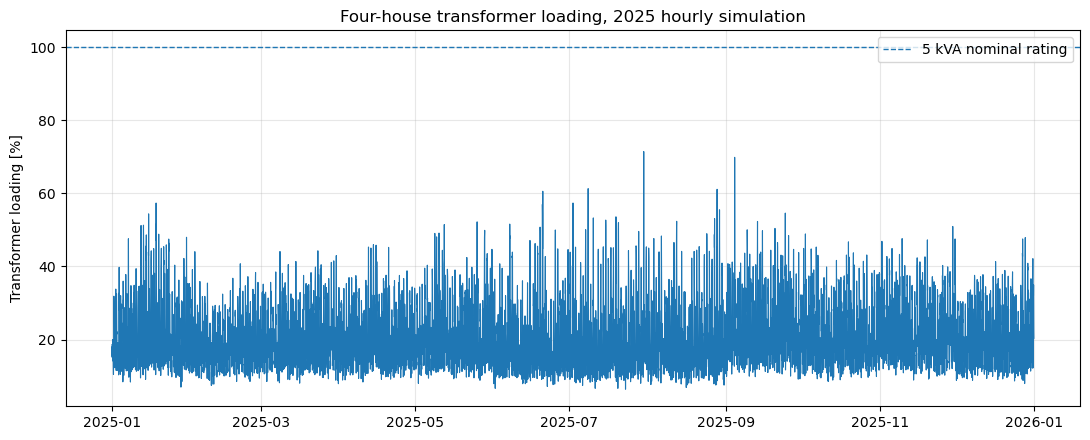

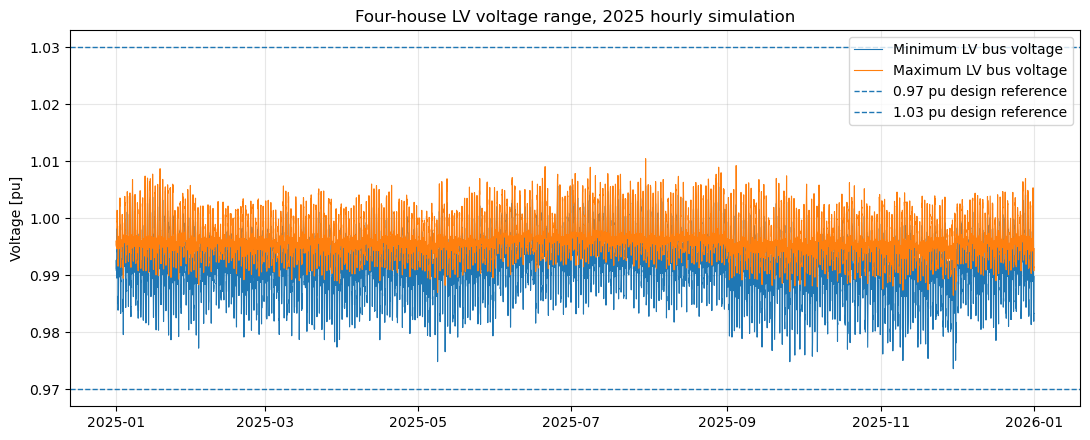

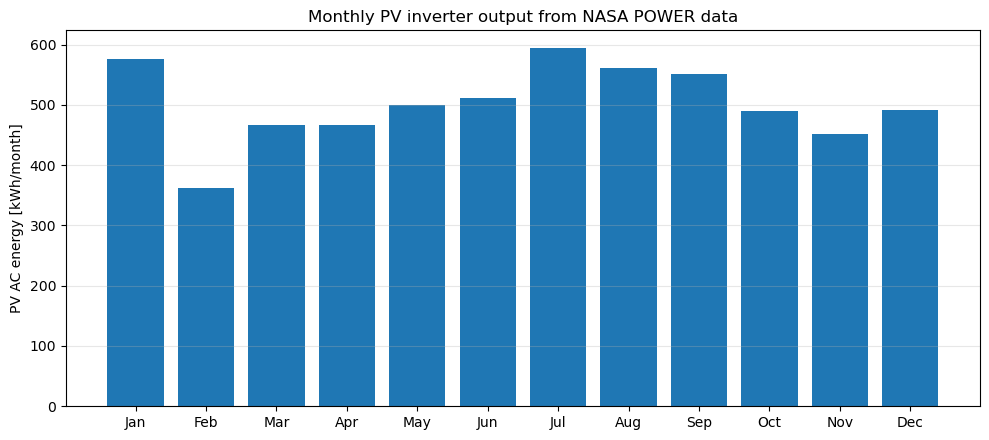

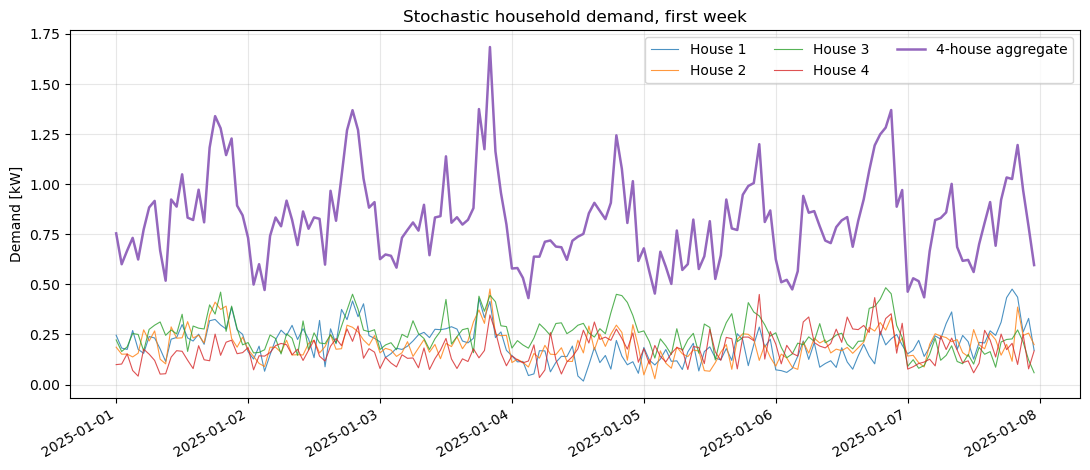

In [13]:
# ============================================================
# 17. NASA ANNUAL REFERENCE PLOTS
# ============================================================

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(
    annual_results["timestamp"],
    annual_results["transformer_loading_pct"],
    linewidth=0.8,
)
ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="5 kVA nominal rating",
)
ax.set_ylabel("Transformer loading [%]")
ax.set_title("Four-house transformer loading, 2025 hourly simulation")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_annual_4hh_transformer_loading.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(
    annual_results["timestamp"],
    annual_results["min_lv_vm_pu"],
    linewidth=0.8,
    label="Minimum LV bus voltage",
)
ax.plot(
    annual_results["timestamp"],
    annual_results["max_lv_vm_pu"],
    linewidth=0.8,
    label="Maximum LV bus voltage",
)
ax.axhline(
    LV_SCREEN_MIN_PU,
    linestyle="--",
    linewidth=1,
    label="0.97 pu design reference",
)
ax.axhline(
    LV_SCREEN_MAX_PU,
    linestyle="--",
    linewidth=1,
    label="1.03 pu design reference",
)
ax.set_ylabel("Voltage [pu]")
ax.set_title("Four-house LV voltage range, 2025 hourly simulation")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_annual_4hh_voltage_envelope.png",
    dpi=180,
)
plt.show()

# Monthly PV energy
monthly_pv = (
    annual_inputs
    .set_index("timestamp")["nasa_pv_ac_kw"]
    .resample("MS")
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(
    monthly_pv.index.strftime("%b"),
    monthly_pv.values,
)
ax.set_ylabel("PV AC energy [kWh/month]")
ax.set_title("Monthly PV inverter output from NASA POWER data")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_monthly_pv_ac_energy.png",
    dpi=180,
)
plt.show()


week = annual_inputs.iloc[:24 * 7]

fig, ax = plt.subplots(figsize=(11, 4.8))

for house in range(1, 5):
    ax.plot(
        week["timestamp"],
        week[f"house_{house}_kw"],
        linewidth=0.8,
        alpha=0.8,
        label=f"House {house}",
    )

ax.plot(
    week["timestamp"],
    week["load_4hh_kw"],
    linewidth=1.8,
    label="4-house aggregate",
)

ax.set_ylabel("Demand [kW]")
ax.set_title("Stochastic household demand, first week")
ax.grid(True, alpha=0.3)
ax.legend(ncol=3)
fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "stochastic_household_demand_first_week.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()


### Maximum-export day

The daily plot below shows the load, PV output and PCC power on the day with the highest annual reverse flow. Positive PCC power is grid import and negative PCC power is export.

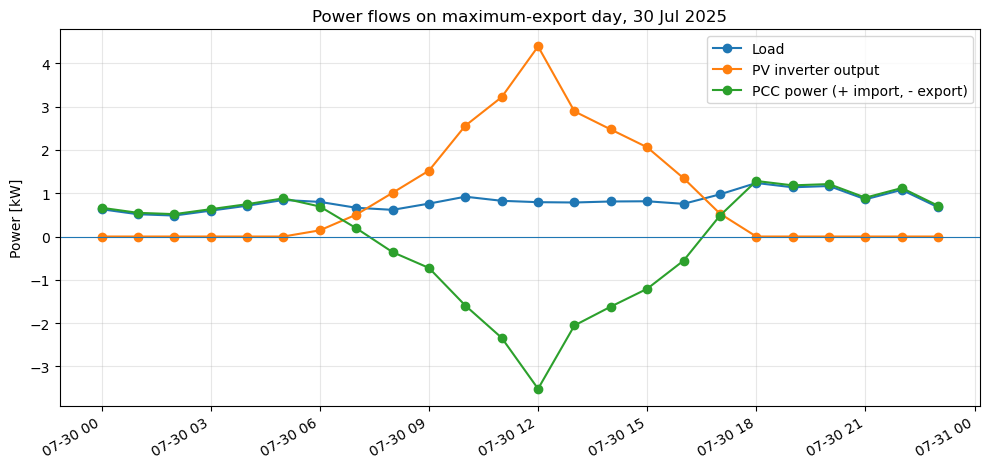

In [14]:
# Day containing the maximum annual reverse flow
max_export_pos = int(
    np.nanargmin(
        annual_results["pcc_import_physical_kw"].to_numpy(dtype=float)
    )
)

max_export_timestamp = pd.Timestamp(
    annual_results.iloc[max_export_pos]["timestamp"]
)

day_start = max_export_timestamp.normalize()
day_end = day_start + pd.Timedelta(days=1)

day_results = annual_results[
    (annual_results["timestamp"] >= day_start)
    & (annual_results["timestamp"] < day_end)
].copy()

fig, ax = plt.subplots(figsize=(10, 4.8))

ax.plot(
    day_results["timestamp"],
    day_results["load_kw"],
    marker="o",
    label="Load",
)

ax.plot(
    day_results["timestamp"],
    day_results["nasa_pv_ac_kw"],
    marker="o",
    label="PV inverter output",
)

ax.plot(
    day_results["timestamp"],
    day_results["pcc_import_physical_kw"],
    marker="o",
    label="PCC power (+ import, - export)",
)

ax.axhline(0.0, linewidth=0.8)
ax.set_ylabel("Power [kW]")
ax.set_title(
    f"Power flows on maximum-export day, {day_start:%d %b %Y}"
)
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "nasa_max_export_day_power_flows.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 18. Four to eight-house sensitivity

The stochastic profiles are the primary demand input.

For each group size, the group consists of houses 1 through N from the same reproducible profile set.

- **Peak demand, no PV:** actual maximum of the N-house stochastic aggregate.
- **NASA annual maximum export:** hour with the largest `PV output - stochastic group load`.
- **Inverter stress:** 4.0, 4.5 and 5.0 kW at the minimum daytime stochastic load for that group.

In [15]:
# ============================================================
# 19. BUILD 4–8-HOUSE STOCHASTIC SCENARIO MATRIX
# ============================================================

scenario_rows = []

for houses in HOUSE_COUNTS:
    group_col = f"load_{houses}hh_kw"

    max_load_idx = annual_inputs[group_col].idxmax()
    max_load_row = annual_inputs.loc[max_load_idx]

    scenario_rows.append({
        "houses": houses,
        "scenario": "MAX_LOAD_NO_DER",
        "timestamp": max_load_row["timestamp"],
        "load_kw": float(max_load_row[group_col]),
        "inverter_ac_kw": 0.0,
    })

    export_margin = (
        annual_inputs["nasa_pv_ac_kw"]
        - annual_inputs[group_col]
    )

    nasa_export_idx = export_margin.idxmax()
    nasa_export_row = annual_inputs.loc[nasa_export_idx]

    scenario_rows.append({
        "houses": houses,
        "scenario": "NASA_MAX_EXPORT_HOURLY",
        "timestamp": nasa_export_row["timestamp"],
        "load_kw": float(nasa_export_row[group_col]),
        "inverter_ac_kw": float(
            nasa_export_row["nasa_pv_ac_kw"]
        ),
    })

    daytime = annual_inputs.loc[
        annual_inputs["timestamp"].dt.hour.between(10, 14)
    ]

    min_day_idx = daytime[group_col].idxmin()
    min_day_row = annual_inputs.loc[min_day_idx]

    for inverter_kw in CLEAR_SKY_INVERTER_KW:
        scenario_rows.append({
            "houses": houses,
            "scenario": f"CLEAR_SKY_{inverter_kw:.1f}KW",
            "timestamp": min_day_row["timestamp"],
            "load_kw": float(min_day_row[group_col]),
            "inverter_ac_kw": inverter_kw,
        })

scenario_matrix = pd.DataFrame(scenario_rows)
display(scenario_matrix.round(4))

,houses,scenario,timestamp,load_kw,inverter_ac_kw
0,4,MAX_LOAD_NO_DER,2025-11-29 20:00:00,2.1667,0.0000
1,4,NASA_MAX_EXPORT_HOURLY,2025-07-30 12:00:00,0.7925,4.3868
2,4,CLEAR_SKY_4.0KW,2025-06-25 13:00:00,0.3207,4.0000
3,4,CLEAR_SKY_4.5KW,2025-06-25 13:00:00,0.3207,4.5000
4,4,CLEAR_SKY_5.0KW,2025-06-25 13:00:00,0.3207,5.0000
5,5,MAX_LOAD_NO_DER,2025-09-27 19:00:00,2.5193,0.0000
6,5,NASA_MAX_EXPORT_HOURLY,2025-07-30 12:00:00,0.9902,4.3868
7,5,CLEAR_SKY_4.0KW,2025-07-11 10:00:00,0.4974,4.0000
8,5,CLEAR_SKY_4.5KW,2025-07-11 10:00:00,0.4974,4.5000
9,5,CLEAR_SKY_5.0KW,2025-07-11 10:00:00,0.4974,5.0000


In [16]:
# ============================================================
# 20. RUN 4–8-HOUSE STOCHASTIC GROUPING SENSITIVITY
# ============================================================

def household_loads_at_timestamp(timestamp, houses):
    row = annual_inputs.loc[
        annual_inputs["timestamp"] == pd.Timestamp(timestamp)
    ]

    if row.empty:
        raise KeyError(f"Timestamp not found: {timestamp}")

    row = row.iloc[0]

    return np.array([
        row[f"house_{h}_kw"]
        for h in range(1, houses + 1)
    ], dtype=float)


grouping_results = []

for row in scenario_matrix.itertuples(index=False):
    house_loads_kw = household_loads_at_timestamp(
        row.timestamp,
        row.houses,
    )

    _, result = run_snapshot(
        houses=row.houses,
        scenario=row.scenario,
        inverter_ac_kw=row.inverter_ac_kw,
        house_loads_kw=house_loads_kw,
    )

    result["timestamp"] = row.timestamp
    result["peak_house_load_kw"] = float(
        house_loads_kw.max()
    )

    grouping_results.append(result)

grouping_results = pd.DataFrame(grouping_results)

display(
    grouping_results[
        [
            "scenario",
            "houses",
            "timestamp",
            "load_kw",
            "peak_house_load_kw",
            "inverter_ac_kw",
            "pcc_import_physical_kw",
            "transformer_loading_pct",
            "transformer_lv_current_a",
            "max_mv_line_loading_pct",
            "max_lv_line_loading_pct",
            "min_lv_vm_pu",
            "max_lv_vm_pu",
            "transformer_nominal_ok",
            "lv_drop_screen_ok",
            "lv_rise_screen_ok",
        ]
    ].round(4)
)

grouping_results.to_csv(
    RESULTS_DIR / "nasa_grouping_4_to_8_house_results.csv",
    index=False,
)

,scenario,houses,timestamp,load_kw,peak_house_load_kw,inverter_ac_kw,pcc_import_physical_kw,transformer_loading_pct,transformer_lv_current_a,max_mv_line_loading_pct,max_lv_line_loading_pct,min_lv_vm_pu,max_lv_vm_pu,transformer_nominal_ok,lv_drop_screen_ok,lv_rise_screen_ok
0,MAX_LOAD_NO_DER,4,2025-11-29 20:00:00,2.1667,0.6061,0.0000,2.2467,50.9661,10.2800,0.1817,6.8533,0.9736,0.9865,True,True,True
1,NASA_MAX_EXPORT_HOURLY,4,2025-07-30 12:00:00,0.7925,0.2354,4.3868,-3.5144,71.4738,14.8904,0.2539,2.4303,1.0057,1.0105,True,True,True
2,CLEAR_SKY_4.0KW,4,2025-06-25 13:00:00,0.3207,0.1261,4.0000,-3.6009,72.7760,15.1617,0.2579,0.9799,1.0098,1.0119,True,True,True
3,CLEAR_SKY_4.5KW,4,2025-06-25 13:00:00,0.3207,0.1261,4.5000,-4.0872,82.5114,17.1899,0.2926,0.9782,1.0115,1.0136,True,True,True
4,CLEAR_SKY_5.0KW,4,2025-06-25 13:00:00,0.3207,0.1261,5.0000,-4.5720,92.2167,19.2118,0.3272,0.9766,1.0132,1.0153,True,True,True
5,MAX_LOAD_NO_DER,5,2025-09-27 19:00:00,2.5193,0.6369,0.0000,2.6101,59.0865,11.9729,0.2107,7.9819,0.9714,0.9843,True,True,True
6,NASA_MAX_EXPORT_HOURLY,5,2025-07-30 12:00:00,0.9902,0.2354,4.3868,-3.3206,67.8887,14.1435,0.2414,3.0392,1.0046,1.0093,True,True,True
7,CLEAR_SKY_4.0KW,5,2025-07-11 10:00:00,0.4974,0.1564,4.0000,-3.4282,69.4470,14.4681,0.2463,1.5210,1.0089,1.0108,True,True,True
8,CLEAR_SKY_4.5KW,5,2025-07-11 10:00:00,0.4974,0.1564,4.5000,-3.9151,79.1849,16.4969,0.2809,1.5185,1.0106,1.0126,True,True,True
9,CLEAR_SKY_5.0KW,5,2025-07-11 10:00:00,0.4974,0.1564,5.0000,-4.4004,88.8953,18.5199,0.3155,1.5159,1.0123,1.0143,True,True,True


### Four-house transformer loading by operating condition

The transformer loading values below refer to different operating conditions:

- **Peak demand, no PV:** forward power flow from the grid to the houses
- **NASA annual max export:** the highest reverse-flow hour in the 2025 NASA series
- **5 kW inverter stress:** full inverter output at minimum daytime load

The annual maximum transformer loading is therefore not expected to equal the peak-demand loading.

In [17]:
four_house_case_comparison = (
    grouping_results[
        (grouping_results["houses"] == 4)
        & grouping_results["scenario"].isin([
            "MAX_LOAD_NO_DER",
            "NASA_MAX_EXPORT_HOURLY",
            "CLEAR_SKY_5.0KW",
        ])
    ]
    .copy()
)

four_house_case_comparison["case"] = (
    four_house_case_comparison["scenario"].map({
        "MAX_LOAD_NO_DER": "Peak demand, no PV",
        "NASA_MAX_EXPORT_HOURLY": "NASA annual max export",
        "CLEAR_SKY_5.0KW": "5 kW inverter stress",
    })
)

display(
    four_house_case_comparison[
        [
            "case",
            "load_kw",
            "inverter_ac_kw",
            "pcc_import_physical_kw",
            "transformer_loading_pct",
            "min_lv_vm_pu",
            "max_lv_vm_pu",
        ]
    ].round(4)
)

,case,load_kw,inverter_ac_kw,pcc_import_physical_kw,transformer_loading_pct,min_lv_vm_pu,max_lv_vm_pu
0,"Peak demand, no PV",2.1667,0.0000,2.2467,50.9661,0.9736,0.9865
1,NASA annual max export,0.7925,4.3868,-3.5144,71.4738,1.0057,1.0105
4,5 kW inverter stress,0.3207,5.0000,-4.5720,92.2167,1.0132,1.0153


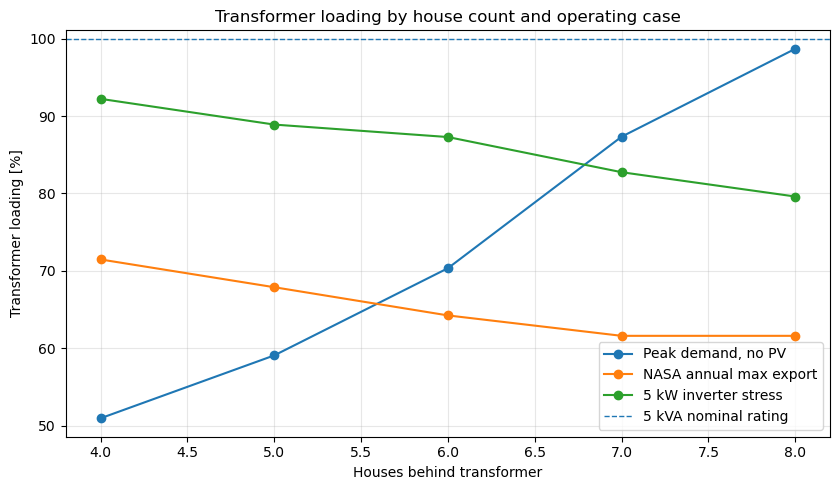

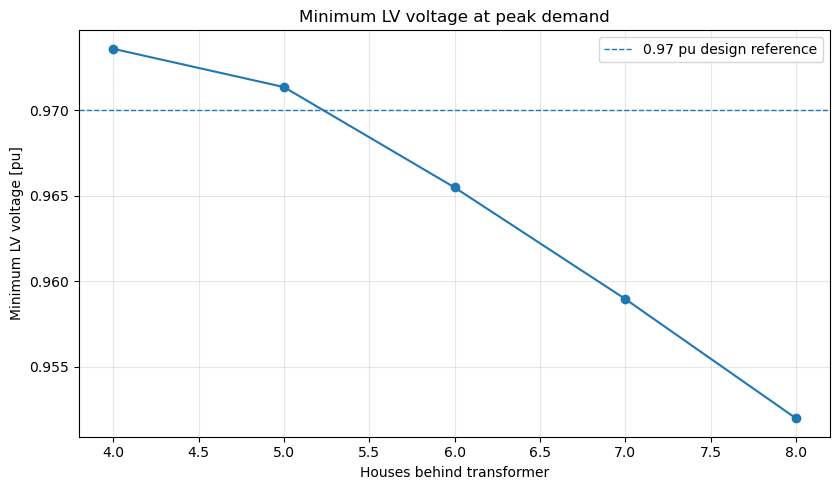

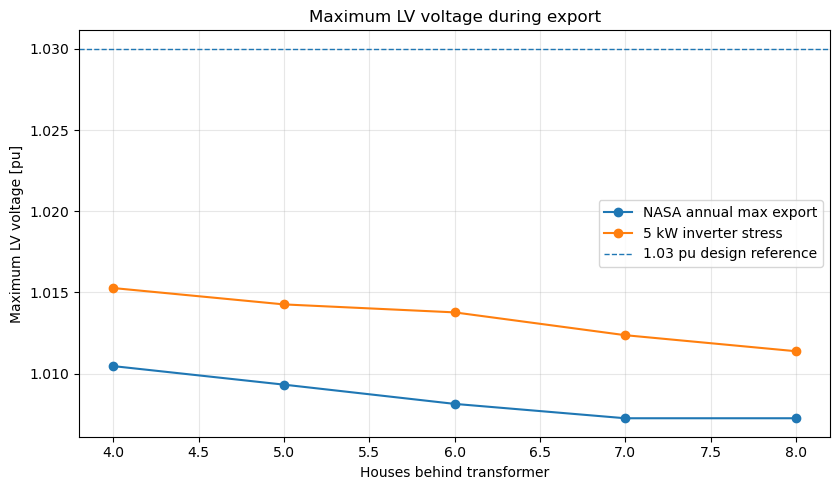

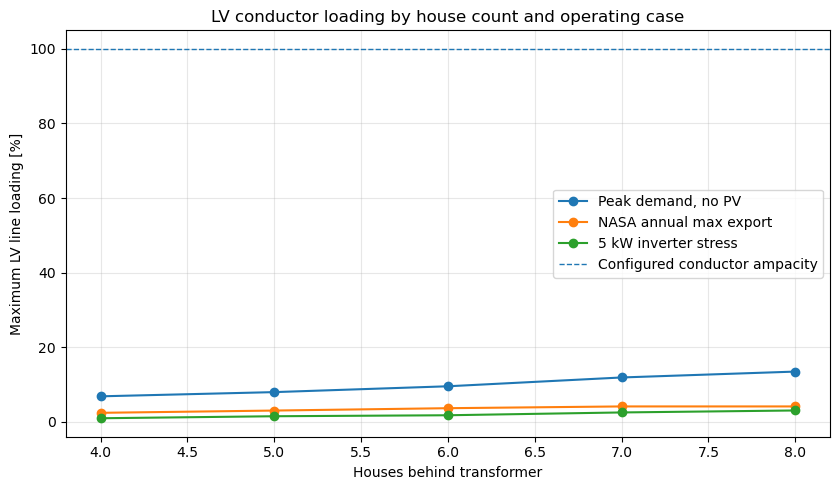

In [18]:
# ============================================================
# 21. GROUPING PLOTS
# ============================================================

def scenario_subset(name):
    return (
        grouping_results[
            grouping_results["scenario"] == name
        ]
        .sort_values("houses")
        .copy()
    )

max_load_results = scenario_subset(
    "MAX_LOAD_NO_DER"
)

nasa_export_results = scenario_subset(
    "NASA_MAX_EXPORT_HOURLY"
)

clear5_results = scenario_subset(
    "CLEAR_SKY_5.0KW"
)

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    max_load_results["houses"],
    max_load_results["transformer_loading_pct"],
    marker="o",
    label="Peak demand, no PV",
)
ax.plot(
    nasa_export_results["houses"],
    nasa_export_results["transformer_loading_pct"],
    marker="o",
    label="NASA annual max export",
)
ax.plot(
    clear5_results["houses"],
    clear5_results["transformer_loading_pct"],
    marker="o",
    label="5 kW inverter stress",
)
ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="5 kVA nominal rating",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Transformer loading [%]")
ax.set_title("Transformer loading by house count and operating case")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_transformer_loading.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    max_load_results["houses"],
    max_load_results["min_lv_vm_pu"],
    marker="o",
)
ax.axhline(
    LV_SCREEN_MIN_PU,
    linestyle="--",
    linewidth=1,
    label="0.97 pu design reference",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Minimum LV voltage [pu]")
ax.set_title("Minimum LV voltage at peak demand")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_max_load_min_voltage.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    nasa_export_results["houses"],
    nasa_export_results["max_lv_vm_pu"],
    marker="o",
    label="NASA annual max export",
)
ax.plot(
    clear5_results["houses"],
    clear5_results["max_lv_vm_pu"],
    marker="o",
    label="5 kW inverter stress",
)
ax.axhline(
    LV_SCREEN_MAX_PU,
    linestyle="--",
    linewidth=1,
    label="1.03 pu design reference",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Maximum LV voltage [pu]")
ax.set_title("Maximum LV voltage during export")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_export_max_voltage.png",
    dpi=180,
)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(
    max_load_results["houses"],
    max_load_results["max_lv_line_loading_pct"],
    marker="o",
    label="Peak demand, no PV",
)
ax.plot(
    nasa_export_results["houses"],
    nasa_export_results["max_lv_line_loading_pct"],
    marker="o",
    label="NASA annual max export",
)
ax.plot(
    clear5_results["houses"],
    clear5_results["max_lv_line_loading_pct"],
    marker="o",
    label="5 kW inverter stress",
)
ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="Configured conductor ampacity",
)
ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Maximum LV line loading [%]")
ax.set_title("LV conductor loading by house count and operating case")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "nasa_grouping_lv_line_loading.png",
    dpi=180,
)
plt.show()

### LV voltage profile for critical cases

The feeder profile shows where the voltage deviation occurs along the representative LV route. Four cases are shown:

- four houses at peak demand
- four houses at the NASA annual maximum-export condition
- four houses at the 5 kW inverter stress condition
- eight houses at peak demand

This plot is based on the representative radial feeder, not surveyed service-drop geometry.

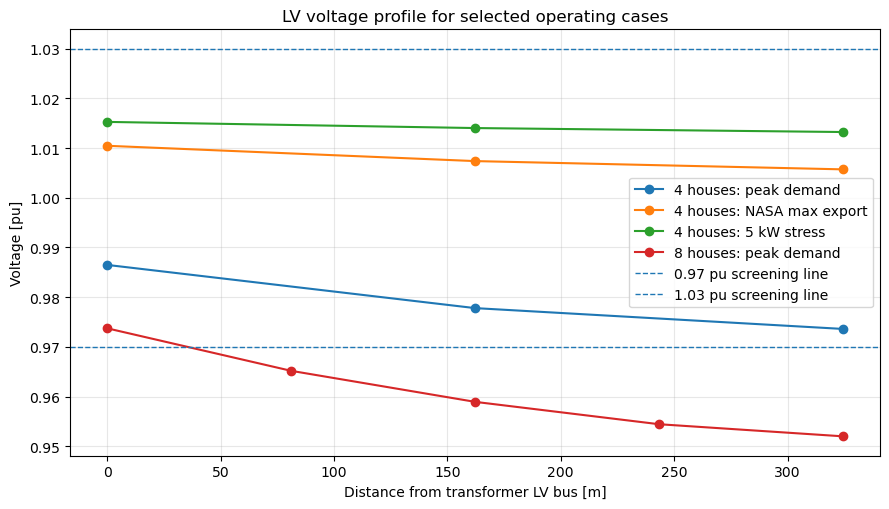

In [19]:
def solve_lv_voltage_profile(
    houses,
    timestamp,
    inverter_ac_kw,
    label,
):
    house_loads_kw = household_loads_at_timestamp(
        timestamp,
        houses,
    )

    net, _ = run_snapshot(
        houses=houses,
        scenario=label,
        inverter_ac_kw=inverter_ac_kw,
        house_loads_kw=house_loads_kw,
    )

    lv_buses = net._san_rafael["lv_bus_indices"]
    n_segments = len(lv_buses) - 1

    distances_m = np.linspace(
        0.0,
        LV_ROUTE_M,
        n_segments + 1,
    )

    vm_pu = (
        net.res_bus.loc[lv_buses, "vm_pu"]
        .to_numpy(dtype=float)
    )

    return pd.DataFrame({
        "distance_m": distances_m,
        "vm_pu": vm_pu,
        "case": label,
    })


def get_group_case(houses, scenario):
    return (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (grouping_results["scenario"] == scenario)
        ]
        .iloc[0]
    )


profile_cases = []

r = get_group_case(4, "MAX_LOAD_NO_DER")
profile_cases.append(
    solve_lv_voltage_profile(
        4,
        r["timestamp"],
        r["inverter_ac_kw"],
        "4 houses: peak demand",
    )
)

r = get_group_case(4, "NASA_MAX_EXPORT_HOURLY")
profile_cases.append(
    solve_lv_voltage_profile(
        4,
        r["timestamp"],
        r["inverter_ac_kw"],
        "4 houses: NASA max export",
    )
)

r = get_group_case(4, "CLEAR_SKY_5.0KW")
profile_cases.append(
    solve_lv_voltage_profile(
        4,
        r["timestamp"],
        r["inverter_ac_kw"],
        "4 houses: 5 kW stress",
    )
)

r = get_group_case(8, "MAX_LOAD_NO_DER")
profile_cases.append(
    solve_lv_voltage_profile(
        8,
        r["timestamp"],
        r["inverter_ac_kw"],
        "8 houses: peak demand",
    )
)

lv_voltage_profiles = pd.concat(
    profile_cases,
    ignore_index=True,
)

fig, ax = plt.subplots(figsize=(9, 5.2))

for case_name, df_case in lv_voltage_profiles.groupby("case", sort=False):
    ax.plot(
        df_case["distance_m"],
        df_case["vm_pu"],
        marker="o",
        label=case_name,
    )

ax.axhline(
    LV_SCREEN_MIN_PU,
    linestyle="--",
    linewidth=1,
    label="0.97 pu screening line",
)

ax.axhline(
    LV_SCREEN_MAX_PU,
    linestyle="--",
    linewidth=1,
    label="1.03 pu screening line",
)

ax.set_xlabel("Distance from transformer LV bus [m]")
ax.set_ylabel("Voltage [pu]")
ax.set_title("LV voltage profile for selected operating cases")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "lv_voltage_profile_critical_cases.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 22. Transformer headroom

The main study covers 4 to 8 houses. The stochastic profile set contains 20 households, so the same demand model can be extended for a transformer-headroom sensitivity.

For each house count, the maximum hourly stochastic aggregate demand is selected and run with no PV support.

,houses,timestamp,load_kw,peak_house_load_kw,transformer_loading_pct,transformer_lv_current_a,max_lv_line_loading_pct,min_lv_vm_pu
0,1,2025-03-30 19:00:00,0.711,0.711,17.657,3.325,2.217,0.990
1,2,2025-09-11 20:00:00,1.174,0.615,28.178,5.526,3.684,0.983
2,3,2025-11-29 20:00:00,1.696,0.606,40.023,7.998,5.332,0.980
3,4,2025-11-29 20:00:00,2.167,0.606,50.966,10.280,6.853,0.974
4,5,2025-09-27 19:00:00,2.519,0.637,59.086,11.973,7.982,0.971
5,6,2025-11-01 19:00:00,2.998,0.569,70.347,14.320,9.547,0.965
6,7,2025-11-01 19:00:00,3.717,0.720,87.330,17.860,11.907,0.959
7,8,2025-11-01 19:00:00,4.183,0.720,98.682,20.226,13.484,0.952
8,9,2025-11-01 19:00:00,4.417,0.720,104.056,21.346,14.230,0.953
9,10,2025-11-01 19:00:00,4.940,0.720,116.979,24.039,16.026,0.945


First nominal transformer overload in the stochastic headroom sweep: 9 houses.


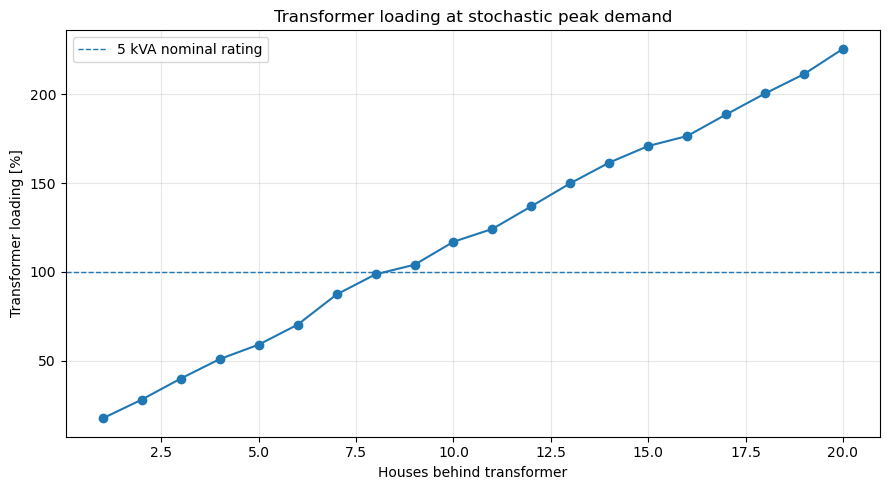

In [20]:
# ============================================================
# 23. STOCHASTIC TRANSFORMER HEADROOM SWEEP
# ============================================================

headroom_rows = []

for houses in HEADROOM_HOUSE_COUNTS:
    group_col = f"load_{houses}hh_kw"

    if group_col not in annual_inputs.columns:
        break

    peak_idx = annual_inputs[group_col].idxmax()
    peak_row = annual_inputs.loc[peak_idx]

    house_loads_kw = np.array([
        peak_row[f"house_{h}_kw"]
        for h in range(1, houses + 1)
    ], dtype=float)

    _, result = run_snapshot(
        houses=houses,
        scenario="HEADROOM_MAX_LOAD_NO_DER",
        inverter_ac_kw=0.0,
        house_loads_kw=house_loads_kw,
    )

    result["timestamp"] = peak_row["timestamp"]
    result["peak_house_load_kw"] = float(
        house_loads_kw.max()
    )

    headroom_rows.append(result)

headroom_results = pd.DataFrame(headroom_rows)

first_overload = headroom_results[
    headroom_results["transformer_loading_pct"] > 100
].head(1)

display(
    headroom_results[
        [
            "houses",
            "timestamp",
            "load_kw",
            "peak_house_load_kw",
            "transformer_loading_pct",
            "transformer_lv_current_a",
            "max_lv_line_loading_pct",
            "min_lv_vm_pu",
        ]
    ].round(3)
)

if not first_overload.empty:
    n = int(first_overload.iloc[0]["houses"])
    print(
        f"First nominal transformer overload in the "
        f"stochastic headroom sweep: {n} houses."
    )
else:
    print(
        "No nominal transformer overload within "
        "the tested stochastic headroom range."
    )

headroom_results.to_csv(
    RESULTS_DIR / "transformer_headroom_house_sweep.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    headroom_results["houses"],
    headroom_results["transformer_loading_pct"],
    marker="o",
)

ax.axhline(
    100,
    linestyle="--",
    linewidth=1,
    label="5 kVA nominal rating",
)

ax.set_xlabel("Houses behind transformer")
ax.set_ylabel("Transformer loading [%]")
ax.set_title("Transformer loading at stochastic peak demand")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "transformer_headroom_house_sweep.png",
    dpi=180,
)

plt.show()

## 24. Spatial grouping files

The spatial data contains proximity-based groupings of the mapped houses for maximum group sizes from 4 to 8.

These are planning groupings only. The house locations are image-derived, individual LV service routes are not surveyed, and the groups are not confirmed EPM transformer allocations.

The electrical sensitivity therefore uses a representative radial LV feeder rather than treating the spatial grouping as surveyed network topology.

In [21]:
# ============================================================
# 24. OPTIONAL SPATIAL GROUPING SUMMARY
# ============================================================

spatial_rows = []

for max_houses in HOUSE_COUNTS:
    path = find_input(
        [
            f"san_rafael_case_{max_houses}_houses_max_house_groups.csv"
        ],
        required=False,
    )

    if path is None:
        continue

    df = pd.read_csv(path)

    group_sizes = (
        df.groupby("group_id")
        .size()
        .sort_values(ascending=False)
    )

    spatial_rows.append({
        "max_houses_case": max_houses,
        "number_of_planning_groups":
            int(group_sizes.size),
        "largest_group":
            int(group_sizes.max()),
        "smallest_group":
            int(group_sizes.min()),
        "group_sizes":
            ", ".join(
                str(int(x))
                for x in group_sizes.tolist()
            ),
        "status":
            "image-derived planning grouping",
    })

spatial_grouping_summary = pd.DataFrame(
    spatial_rows
)

if spatial_grouping_summary.empty:
    print(
        "No spatial grouping files were found."
    )
else:
    display(spatial_grouping_summary)

    spatial_grouping_summary.to_csv(
        RESULTS_DIR / "spatial_grouping_summary.csv",
        index=False,
    )

,max_houses_case,number_of_planning_groups,largest_group,smallest_group,group_sizes,status
0,4,9,4,3,"4, 4, 4, 4, 4, 4, 4, 4, 3",image-derived planning grouping
1,5,7,5,5,"5, 5, 5, 5, 5, 5, 5",image-derived planning grouping
2,6,6,6,5,"6, 6, 6, 6, 6, 5",image-derived planning grouping
3,7,5,7,7,"7, 7, 7, 7, 7",image-derived planning grouping
4,8,5,8,4,"8, 8, 8, 7, 4",image-derived planning grouping


## 26. Interpretation notes

### Transformer loading

`transformer_loading_pct > 100%` means the calculated apparent-power flow exceeds the 5 kVA nominal transformer rating.

The 120% factor shown in EPM RA4-100 is used for metering/CT selection and is not treated here as a continuous transformer loading limit.

### LV line loading

Line loading depends on the assumed 1/0 AAC ampacity. Since the exact installation-specific ampacity is not available, the percentage is a screening result.

### Voltage

The 0.97 and 1.03 pu lines are used as a 3% design-screening band based on RA8-017. They are not presented as the complete Colombian statutory service-voltage limits.

### Export cases

The NASA annual case represents the highest reverse flow found in the 2025 weather year. The 4.0, 4.5 and 5.0 kW cases are equipment-limit stress checks.

In [22]:
# ============================================================
# 27. EXPORT A COMPACT NASA TECHNICAL SUMMARY
# ============================================================

summary_rows = []

for houses in HOUSE_COUNTS:
    import_row = (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (
                grouping_results["scenario"]
                == "MAX_LOAD_NO_DER"
            )
        ]
        .iloc[0]
    )

    nasa_row = (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (
                grouping_results["scenario"]
                == "NASA_MAX_EXPORT_HOURLY"
            )
        ]
        .iloc[0]
    )

    clear5_row = (
        grouping_results[
            (grouping_results["houses"] == houses)
            & (
                grouping_results["scenario"]
                == "CLEAR_SKY_5.0KW"
            )
        ]
        .iloc[0]
    )

    summary_rows.append({
        "houses": houses,

        "max_load_trafo_loading_pct":
            import_row["transformer_loading_pct"],
        "max_load_min_lv_vm_pu":
            import_row["min_lv_vm_pu"],
        "max_load_lv_line_loading_pct":
            import_row["max_lv_line_loading_pct"],

        "nasa_max_export_timestamp":
            nasa_row["timestamp"],
        "nasa_max_export_inverter_kw":
            nasa_row["inverter_ac_kw"],
        "nasa_max_export_pcc_kw":
            nasa_row["pcc_import_physical_kw"],
        "nasa_max_export_trafo_loading_pct":
            nasa_row["transformer_loading_pct"],
        "nasa_max_export_max_lv_vm_pu":
            nasa_row["max_lv_vm_pu"],
        "nasa_max_export_lv_line_loading_pct":
            nasa_row["max_lv_line_loading_pct"],

        "deterministic_5kw_trafo_loading_pct":
            clear5_row["transformer_loading_pct"],
        "deterministic_5kw_max_lv_vm_pu":
            clear5_row["max_lv_vm_pu"],
        "deterministic_5kw_lv_line_loading_pct":
            clear5_row["max_lv_line_loading_pct"],
        "deterministic_5kw_pcc_import_kw":
            clear5_row["pcc_import_physical_kw"],
    })

technical_summary = pd.DataFrame(
    summary_rows
)

display(technical_summary.round(4))

technical_summary.to_csv(
    RESULTS_DIR / "nasa_pandapower_4_to_8_house_summary.csv",
    index=False,
)

print(
    f"\nResults written to: {RESULTS_DIR.resolve()}"
)
print(
    f"Figures written to: {FIGURES_DIR.resolve()}"
)

,houses,max_load_trafo_loading_pct,max_load_min_lv_vm_pu,max_load_lv_line_loading_pct,nasa_max_export_timestamp,nasa_max_export_inverter_kw,nasa_max_export_pcc_kw,nasa_max_export_trafo_loading_pct,nasa_max_export_max_lv_vm_pu,nasa_max_export_lv_line_loading_pct,deterministic_5kw_trafo_loading_pct,deterministic_5kw_max_lv_vm_pu,deterministic_5kw_lv_line_loading_pct,deterministic_5kw_pcc_import_kw
0,4,50.9661,0.9736,6.8533,2025-07-30 12:00:00,4.3868,-3.5144,71.4738,1.0105,2.4303,92.2167,1.0153,0.9766,-4.5720
1,5,59.0865,0.9714,7.9819,2025-07-30 12:00:00,4.3868,-3.3206,67.8887,1.0093,3.0392,88.8953,1.0143,1.5159,-4.4004
2,6,70.3465,0.9655,9.5468,2025-07-30 12:00:00,4.3868,-3.1189,64.2470,1.0081,3.6721,87.2849,1.0138,1.7792,-4.3166
3,7,87.3295,0.9590,11.9066,2025-07-30 12:00:00,4.3868,-2.9690,61.6111,1.0073,4.1438,82.7430,1.0124,2.5318,-4.0772
4,8,98.6817,0.9520,13.4840,2025-07-30 12:00:00,4.3868,-2.9690,61.6111,1.0073,4.1438,79.6024,1.0114,3.0609,-3.9089



Results written to: D:\0. UoL\SEEDExchange\sanrafaelutility-main\pandapower_results_nasa
Figures written to: D:\0. UoL\SEEDExchange\sanrafaelutility-main\pandapower_results_nasa\figures


## 28. Study limits

The network model combines EPM asset information, image-derived route lengths, NASA POWER solar data and synthetic household demand variability.

The demand profiles use the **20% day-to-day** and **25% timestep** variability settings stored in the final HOMER XML. Each household receives an independent reproducible realization and is normalized to the same annual energy target.

The original HOMER random seed is not available, so the exact HOMER hourly realization cannot be reproduced.

Other limitations are:

- transformer 94022 nameplate impedance and loss data are not available;
- the LV route is representative rather than surveyed house-by-house;
- 1/0 AAC ampacity and reactance are screening assumptions;
- stochastic household profiles are synthetic, not measured annual household time series.